# Última auditoría histórica y decisión de ubicación

**Recomendación: mantener Seventh Avenue/W29–W30 y comenzar una base ficticia con supuestos explícitos.** El histórico no añade mediciones en los accesos exactos; esto limita la calibración, pero no impide cumplir el requisito académico de al menos 1 000 registros y 12–20 variables.

No se generan datos sintéticos ni se implementa SimPy en esta auditoría. La búsqueda queda cerrada para pasar a la generación.

## 1. Fuentes y consultas

- [Traffic Volume Counts (Historical), btm5-ppia](https://data.cityofnewyork.us/Transportation/Traffic-Volume-Counts-Historical-/btm5-ppia): una fila diaria con 24 columnas horarias; no tiene geometría ni campo de borough.
- [Automated Traffic Volume Counts, 7ym2-wayt](https://data.cityofnewyork.us/Transportation/Automated-Traffic-Volume-Counts/7ym2-wayt): una fila por intervalo de 15 minutos. Se vuelve a consultar solo para los IDs comparados.
- [LION de DCP](https://services5.arcgis.com/GfwWNkhOj9bNBqoJ/ArcGIS/rest/services/LION/FeatureServer/0): identificación espacial y accesos por nodos, no solo por nombres.
- [Peticiones SODA 3.0](https://dev.socrata.com/docs/queries/): POST con `requests`; App Token en encabezado, sin Secret Token ni credenciales en resultados.

El helper nuevo reutiliza la carga segura de credenciales de la primera auditoría. Caché local: `resultados/auditoria_historico_complementario/`. Cambiar `ACTUALIZAR` a `True` para consultar nuevamente; los textos y la conclusión corresponden a la evidencia entregada.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

RAIZ=Path.cwd().resolve()
if RAIZ.name=='notebooks':
    RAIZ=RAIZ.parent
sys.path.insert(0,str(RAIZ/'src'))
from auditoria_historicos import OBJETIVO
from auditoria_complementaria import obtener_complemento,W23,REFERENCIAS,IDS

ACTUALIZAR=False
SALIDA=obtener_complemento(RAIZ,actualizar=ACTUALIZAR)
def leer(nombre):
    return json.loads((SALIDA/f'{nombre}.json').read_text())

display(pd.Series(leer('manifest'),name='Consulta'))
esquema=leer('esquema')
columnas=pd.DataFrame([{'columna':c['fieldName'],'tipo':c['dataTypeName'],'descripcion':c.get('description','')}
                       for c in esquema['columns'] if not c['fieldName'].startswith(':')])
display(columnas.head(7))
# Correspondencia explícita hora-columna: no inferir la hora por orden alfabético.
HORAS=(['_12_00_1_00_am']+[f'_{i}_00_{i+1}_00am' for i in range(1,11)]
       +['_11_00_12_00pm','_12_00_1_00pm']+[f'_{i}_00_{i+1}_00pm' for i in range(1,11)]
       +['_11_00_12_00am'])
assert len(HORAS)==24 and set(HORAS).issubset(columnas.columna)
display(pd.DataFrame({'hora_inicio':range(24),'columna':HORAS}).T)
display(pd.DataFrame(leer('global')))
consultas=pd.DataFrame(leer('consultas'))
display(consultas[['nombre','dataset','query','page','filas']].drop_duplicates('nombre'))

fecha_consulta                      2026-11-08T00:06:29.611107-06:00
datasets                                      [btm5-ppia, 7ym2-wayt]
ids_consultados    [32830, 33637, 33638, 33639, 33652, 33800, 338...
nota               Dos fuentes separadas. No se mezclan años ni c...
Name: Consulta, dtype: object

,columna,tipo,descripcion
0,id,text,Count ID
1,segmentid,number,"LION Segment ID. Called ""GIS ID' in the 2011-1..."
2,roadway_name,text,Street name
3,from,text,Intersecting street name at one end of street
4,to,text,Intersecting street name at other end of street
5,direction,text,Compass direction
6,date,calendar_date,Date of the traffic count


,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
hora_inicio,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
columna,_12_00_1_00_am,_1_00_2_00am,_2_00_3_00am,_3_00_4_00am,_4_00_5_00am,_5_00_6_00am,_6_00_7_00am,_7_00_8_00am,_8_00_9_00am,_9_00_10_00am,...,_2_00_3_00pm,_3_00_4_00pm,_4_00_5_00pm,_5_00_6_00pm,_6_00_7_00pm,_7_00_8_00pm,_8_00_9_00pm,_9_00_10_00pm,_10_00_11_00pm,_11_00_12_00am


,n,inicio,fin
0,42756,2012-01-08T00:00:00.000,2021-05-09T00:00:00.000


,nombre,dataset,query,page,filas
0,global,btm5-ppia,"SELECT count(*) AS n, min(date) AS inicio, max...","{'pageNumber': 1, 'pageSize': 1000}",1
1,muestra,btm5-ppia,SELECT * LIMIT 1,"{'pageNumber': 1, 'pageSize': 1000}",1
2,inventario,btm5-ppia,"SELECT segmentid, roadway_name, `from`, `to`, ...","{'pageNumber': 1, 'pageSize': 1000}",157
3,conteos,btm5-ppia,"SELECT * WHERE segmentid IN (33800,33801,33802...","{'pageNumber': 1, 'pageSize': 1000}",0
4,resumen_ids,btm5-ppia,"SELECT segmentid, roadway_name, `from`, `to`, ...","{'pageNumber': 1, 'pageSize': 1000}",8
5,conteos_referencia,btm5-ppia,"SELECT * WHERE segmentid IN (32830,33637,33638...","{'pageNumber': 1, 'pageSize': 1000}",78
6,primaria,7ym2-wayt,"SELECT * WHERE segmentid IN (32830,33637,33638...","{'pageNumber': 1, 'pageSize': 1000}",1000


## 2. Correspondencia espacial

Se buscaron variantes de Seventh, 7, 23, 29 y 30: **157 combinaciones de nombre, límites, ID y sentido** en el histórico. Se cruzaron los IDs con LION y se consultaron directamente todos los segmentos originales.

Además se obtuvieron **todos los segmentos de calle que tocan los nodos 21334 (W29), 21335 (W30) y 21247 (W23)**, independientemente del nombre. Los accesos obtenidos están incluidos en la selección: no se encontraron accesos adicionales en esa comprobación.

Las tres referencias históricas cercanas son otros tramos. Están en Manhattan según LION, pero no deben asignarse a los accesos exactos. `33891` y `34013` están entre Fifth y Broadway, con otras intersecciones entre esos contadores y Seventh. `33652` está al sur del corredor. La versión actual de LION no certifica todos los atributos históricos.

Combinaciones del inventario: 157
Combinaciones sin SegmentID: 0


,SegmentID,Street,NodeIDFrom,NodeIDTo,TrafDir
0,0033894,WEST 29 STREET,0021380,0021334,W
1,0033638,WEST 23 STREET,0021247,0021187,T
2,0033803,WEST 30 STREET,0021335,0021256,A
3,0033639,7 AVENUE,0021247,0021248,A
4,0033637,7 AVENUE,0021246,0021247,A
5,0033802,7 AVENUE,0021334,0021335,A
6,0033804,7 AVENUE,0021335,0021337,A
7,0033896,WEST 30 STREET,0021381,0021335,A
10,0033801,WEST 29 STREET,0021334,0021255,W
11,0032830,WEST 23 STREET,0020752,0021247,T


,Street,NodeIDFrom,NodeIDTo,TrafDir,LBoro,RBoro,XFrom,YFrom,XTo,YTo
segmentid,,,,,,,,,,
33652,7 AVENUE,0021254,0021333,A,1,1,985964,211290,986090,211515
33891,WEST 29 STREET,0021379,0021384,W,1,1,987895,210810,987411,211078
34013,WEST 30 STREET,0021440,0021385,A,1,1,988020,211036,987450,211352


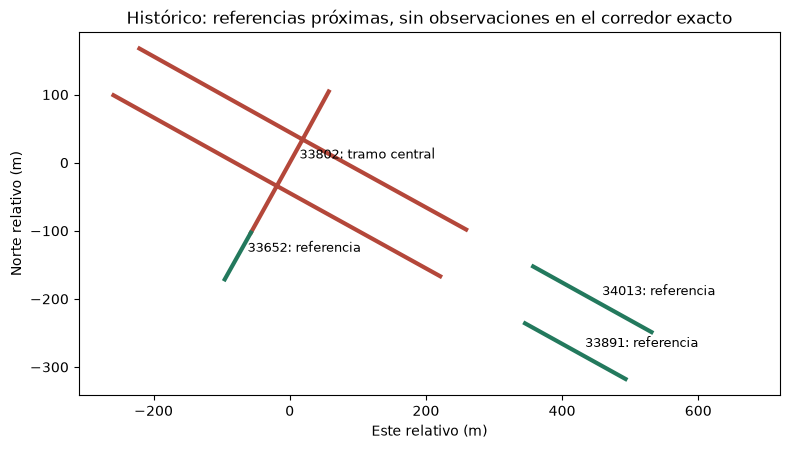

In [2]:
inv=pd.DataFrame(leer('inventario'))
print('Combinaciones del inventario:',len(inv))
print('Combinaciones sin SegmentID:',int(inv.segmentid.isna().sum()))
geo=pd.DataFrame([f['attributes'] for f in leer('lion_correspondencia')['features']])
geo['segmentid']=geo.SegmentID.astype(int)
geo=geo.drop_duplicates('segmentid').set_index('segmentid')
accesos=pd.DataFrame([f['attributes'] for f in leer('lion_accesos')['features']]).drop_duplicates('SegmentID')
assert set(accesos.SegmentID.astype(int)).issubset(set(IDS))
assert {geo.loc[33802,'NodeIDFrom'],geo.loc[33802,'NodeIDTo']}=={'0021334','0021335'}
assert {geo.loc[33637,'NodeIDFrom'],geo.loc[33637,'NodeIDTo']}=={'0021246','0021247'}
display(accesos[['SegmentID','Street','NodeIDFrom','NodeIDTo','TrafDir']])
espacial=geo.loc[list(REFERENCIAS),['Street','NodeIDFrom','NodeIDTo','TrafDir','LBoro','RBoro','XFrom','YFrom','XTo','YTo']]
display(espacial)
espacial.to_csv(SALIDA/'correspondencia_espacial.csv')

fig,ax=plt.subplots(figsize=(8,6))
for sid,text in {**OBJETIVO,**REFERENCIAS}.items():
    row=geo.loc[sid]
    x=np.array([row.XFrom,row.XTo],dtype=float);y=np.array([row.YFrom,row.YTo],dtype=float)
    color='#23795d' if sid in REFERENCIAS else '#b4473a'
    ax.plot((x-986277)*.3048,(y-211852)*.3048,color=color,lw=3)
    if sid in REFERENCIAS or sid==33802:
        ax.annotate(f'{sid}: '+('referencia' if sid in REFERENCIAS else 'tramo central'),
                    (((x.mean()-986277)*.3048),((y.mean()-211852)*.3048)),xytext=(7,3),textcoords='offset points',fontsize=9)
ax.set(xlabel='Este relativo (m)',ylabel='Norte relativo (m)',title='Histórico: referencias próximas, sin observaciones en el corredor exacto')
ax.set_xlim(-310,720)
ax.set_aspect('equal');fig.tight_layout();fig.savefig(SALIDA/'mapa_referencias.png',dpi=140);plt.show()

## 3. Unidades y control de calidad

No se suman filas diarias y filas de 15 minutos como si fueran el mismo tipo de registro. El histórico se transforma a horas únicamente mediante sus columnas explícitas, sin interpolar cuartos de hora. Una hora primaria se usa en la comparación solo si sus cuatro cuartos están presentes, sin combinar solicitudes.

En el histórico, `id` es Count ID. No es globalmente único ni garantiza una campaña: se separan bloques contiguos por segmento, sentido y Count ID. Por ejemplo, ID 98 aparece en dos segmentos y años diferentes.

Las 24 columnas representan horas **nominales** de reloj; no prueban cobertura de las 25 horas físicas de un día de cambio de horario.

In [3]:
raw_h=pd.DataFrame(leer('conteos_referencia'))
h=raw_h.copy()
h['segmentid']=pd.to_numeric(h.segmentid,errors='raise').astype(int)
h['date']=pd.to_datetime(h.date,errors='raise')
for col in HORAS:
    h[col]=pd.to_numeric(h[col],errors='coerce')
assert set(h.segmentid).issubset(set(IDS))
# Verificación de la descarga contra la agregación independiente del servidor.
resumen=pd.DataFrame(leer('resumen_ids'))
resumen['segmentid']=resumen.segmentid.astype(int);resumen['n']=resumen.n.astype(int)
assert h.groupby('segmentid').size().to_dict()==resumen.groupby('segmentid').n.sum().to_dict()
assert len(leer('conteos'))==0, 'El histórico cambió: revisar conclusión sobre los IDs exactos.'

raw_p=pd.DataFrame(leer('primaria'))
p=raw_p.copy()
for col in ['segmentid','requestid','yr','m','d','hh','mm','vol']:
    p[col]=pd.to_numeric(p[col],errors='raise')
p['instante']=pd.to_datetime(dict(year=p.yr,month=p.m,day=p.d))+pd.to_timedelta(p.hh,unit='h')+pd.to_timedelta(p.mm,unit='min')
assert p.mm.isin([0,15,30,45]).all()
calidad=pd.DataFrame([
    {'fuente':'btm5-ppia','filas':len(h),'nulos':int(raw_h.isna().sum().sum()),
     'duplicados_exactos':int(raw_h.duplicated().sum()),
     'duplicados_clave':int(h.duplicated(['segmentid','direction','date']).sum()),
     'volumenes_invalidos':int((h[HORAS].isna()|(h[HORAS]<0)|(h[HORAS]%1!=0)).sum().sum())},
    {'fuente':'7ym2-wayt','filas':len(p),'nulos':int(raw_p.isna().sum().sum()),
     'duplicados_exactos':int(raw_p.duplicated().sum()),
     'duplicados_clave':int(p.duplicated(['segmentid','direction','instante']).sum()),
     'volumenes_invalidos':int((p.vol.isna()|(p.vol<0)|(p.vol%1!=0)).sum())}])
display(calidad);calidad.to_csv(SALIDA/'calidad.csv',index=False)
# Conservar y señalar el texto discrepante; no corregir la fuente silenciosamente.
h['advertencia_ubicacion']=(h.segmentid==33652)&(h['from'].str.contains('East',case=False)|h['to'].str.contains('East',case=False))
print('Filas con East 27/28 frente a segmento LION West 27/28:',int(h.advertencia_ubicacion.sum()))
display(h.loc[h.advertencia_ubicacion,['segmentid','id','date','roadway_name','from','to']].head())

hora_por_columna=dict(zip(HORAS,range(24)))
hlong=h.melt(id_vars=['id','segmentid','direction','date','advertencia_ubicacion'],value_vars=HORAS,var_name='columna_hora',value_name='volumen')
hlong['hora']=hlong.columna_hora.map(hora_por_columna)
hlong['instante']=hlong.date+pd.to_timedelta(hlong.hora,unit='h')
assert len(hlong)==len(h)*24
hlong.to_csv(SALIDA/'historico_horario.csv',index=False)

keys=['segmentid','direction','instante']
p['hora']=p.instante.dt.floor('h')
ph=p.groupby(['segmentid','requestid','direction','hora']).agg(n=('vol','size'),minutos=('mm',lambda v:tuple(sorted(v))),volumen=('vol','sum')).reset_index()
ph=ph[(ph.n==4)&(ph.minutos== (0,15,30,45))].rename(columns={'hora':'instante'})
assert not ph.duplicated(keys).any()
assert not hlong.duplicated(keys).any()
coincidencias=hlong.merge(ph,on=keys,suffixes=('_historico','_primaria'),validate='one_to_one')
print('Horas comparables de histórico:',len(hlong),'de primaria:',len(ph))
print('Claves coincidentes entre fuentes:',len(coincidencias))
print('Mismo volumen en claves coincidentes:',int((coincidencias.volumen_historico==coincidencias.volumen_primaria).sum()))
coincidencias.to_csv(SALIDA/'coincidencias_entre_fuentes.csv',index=False)

,fuente,filas,nulos,duplicados_exactos,duplicados_clave,volumenes_invalidos
0,btm5-ppia,78,0,0,0,0
1,7ym2-wayt,1300,0,0,0,0


Filas con East 27/28 frente a segmento LION West 27/28: 9


,segmentid,id,date,roadway_name,from,to
17,33652,371,2020-11-14,7th AVENUE,East 27th Street,East 28th Street
18,33652,371,2020-11-15,7th AVENUE,East 27th Street,East 28th Street
19,33652,371,2020-11-16,7th AVENUE,East 27th Street,East 28th Street
20,33652,371,2020-11-17,7th AVENUE,East 27th Street,East 28th Street
21,33652,371,2020-11-18,7th AVENUE,East 27th Street,East 28th Street


Horas comparables de histórico: 1872 de primaria: 323
Claves coincidentes entre fuentes: 0
Mismo volumen en claves coincidentes: 0


## 4. Comparación en los emplazamientos exactos

**W29–W30:** el histórico añade cero días en los siete tramos. Sigue disponible solo el acceso WB de W29, con 288 cuartos de hora del 22–24 de abril de 2019.

**W23:** el histórico tampoco añade mediciones en sus tres accesos ni en la salida SB. En la fuente primaria se conservan 790 intervalos SB, 110 WB y 112 EB de septiembre de 2011. Se comprueba su coincidencia real; no se presenta como una campaña de años posteriores.

In [4]:
def tabla_lugar(lugar):
    rows=[]
    for sid,text in lugar.items():
        g=p[p.segmentid==sid];gh=h[h.segmentid==sid]
        rows.append({'segmentid':sid,'tramo':text,'cuartos_primaria':len(g),'dias_historico':len(gh),
                     'inicio_primaria':g.instante.min(),'fin_primaria':g.instante.max(),
                     'dias_primaria':g.instante.dt.date.nunique(),
                     'direccion_primaria':', '.join(sorted(g.direction.unique())),
                     'solicitudes_primaria':', '.join(map(str,sorted(g.requestid.unique())))})
    return pd.DataFrame(rows)

tabla_original=tabla_lugar(OBJETIVO);tabla_23=tabla_lugar(W23)
display(tabla_original);display(tabla_23)
tabla_original.to_csv(SALIDA/'comparacion_w29_w30.csv',index=False)
tabla_23.to_csv(SALIDA/'comparacion_w23.csv',index=False)
entradas_original=[33804,33803,33802,33894]
sets_original=[set(p.loc[p.segmentid==sid,'instante']) for sid in entradas_original]
print('W29–W30, intervalos comunes en cuatro accesos:',len(set.intersection(*sets_original)))
ids_23=[33639,32830,33638]
sets_23=[set(p.loc[p.segmentid==sid,'instante']) for sid in ids_23]
comunes_23=sorted(set.intersection(*sets_23))
print('W23, intervalos comunes en tres accesos:',len(comunes_23))
print('Desde',min(comunes_23),'hasta',max(comunes_23))
horas_23=pd.Series(comunes_23).dt.floor('h').value_counts()
print('W23, horas completas simultáneas:',int(horas_23.eq(4).sum()))
assert len(comunes_23)==95 and horas_23.eq(4).sum()==23

,segmentid,tramo,cuartos_primaria,dias_historico,inicio_primaria,fin_primaria,dias_primaria,direccion_primaria,solicitudes_primaria
0,33804,"7 Av, W30–W31: entrada sur a W30",0,0,NaT,NaT,0,,
1,33803,"W30, 8–7 Av: entrada este a W30",0,0,NaT,NaT,0,,
2,33802,"7 Av, W29–W30: tramo central / entrada sur a W29",0,0,NaT,NaT,0,,
3,33894,"W29, 6–7 Av: entrada oeste a W29",288,0,2019-04-22,2019-04-24 23:45:00,3,WB,30130
4,33800,"7 Av, W28–W29: salida sur de W29",0,0,NaT,NaT,0,,
5,33801,"W29, 7–8 Av: salida oeste de W29",0,0,NaT,NaT,0,,
6,33896,"W30, 7–6 Av: salida este de W30",0,0,NaT,NaT,0,,


,segmentid,tramo,cuartos_primaria,dias_historico,inicio_primaria,fin_primaria,dias_primaria,direccion_primaria,solicitudes_primaria
0,33639,"Seventh W23–W24, entrada SB",790,0,2011-09-11 21:15:00,2011-09-20 02:30:00,10,SB,12558
1,32830,"W23 Sixth–Seventh, entrada WB",110,0,2011-09-19 02:45:00,2011-09-20 06:00:00,2,WB,12559
2,33638,"W23 Seventh–Eighth, entrada EB",112,0,2011-09-19 03:00:00,2011-09-20 06:45:00,2,EB,12560
3,33637,"Seventh W22–W23, salida SB",0,0,NaT,NaT,0,,


W29–W30, intervalos comunes en cuatro accesos: 0
W23, intervalos comunes en tres accesos: 95
Desde 2011-09-19 03:00:00 hasta 2011-09-20 02:30:00
W23, horas completas simultáneas: 23


## 5. Campañas de referencia: mantener separadas

Los **78 días-segmento** corresponden a tres ubicaciones, **26 por ubicación**; no son 78 días independientes. Hay **1 872 conteos horarios nominales** y nueve bloques de conteo (tres por ubicación).

- 33652 SB: 30 septiembre–7 octubre 2012; 28 octubre–5 noviembre 2017; 14–22 noviembre 2020.
- 33891 WB: 30 septiembre–7 octubre 2012; 12–20 noviembre 2016; 5–13 octubre 2019.
- 34013 EB: mismas fechas que 33652.

Se distinguen todos los bloques. Ni el mismo año ni el mismo Count ID implican simultaneidad. El bloque 2020 de 33652 tiene nueve etiquetas espaciales discrepantes y el contexto pandémico; no se recomienda usarlo como referencia principal sin aclaración.

Las tres referencias sí coinciden en **192 horas nominales del 30 septiembre al 7 octubre de 2012**. Son otras ubicaciones, no un reemplazo de los accesos de W29–W30. No coinciden temporalmente con el acceso original observado en abril de 2019.

,segmentid,direction,id,bloque,inicio,fin,dias,horas,advertencias,min_veh_h,max_veh_h,media_veh_h,dias_entre_extremos,dias_sin_registro
0,33652,SB,140,0,2012-09-30,2012-10-07,8,192,0,404.0,1712.0,1218.07,8,0
2,33652,SB,98,0,2017-10-28,2017-11-05,9,216,0,375.0,1543.0,1066.32,9,0
1,33652,SB,371,0,2020-11-14,2020-11-22,9,216,9,175.0,1155.0,752.30,9,0
3,33891,WB,146,0,2012-09-30,2012-10-07,8,192,0,77.0,648.0,395.94,8,0
5,33891,WB,98,0,2016-11-12,2016-11-20,9,216,0,54.0,645.0,319.51,9,0
4,33891,WB,356,0,2019-10-05,2019-10-13,9,216,0,44.0,343.0,218.61,9,0
7,34013,EB,149,0,2012-09-30,2012-10-07,8,192,0,24.0,535.0,304.11,8,0
6,34013,EB,100,0,2017-10-28,2017-11-05,9,216,0,21.0,497.0,275.50,9,0
8,34013,EB,347,0,2020-11-14,2020-11-22,9,216,0,8.0,686.0,231.47,9,0


Referencias: horas comunes en las tres ubicaciones: 192
Desde 2012-09-30 00:00:00 hasta 2012-10-07 23:00:00
Solapamiento temporal con 33894 de abril 2019: 0


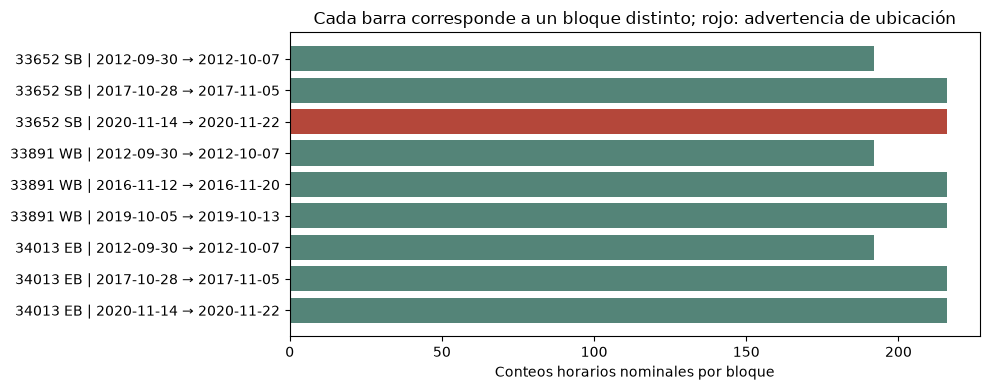

In [5]:
h=h.sort_values(['segmentid','direction','id','date']).copy()
grupo=['segmentid','direction','id']
h['salto']=h.groupby(grupo).date.diff().dt.days.gt(1)
h['bloque']=h.groupby(grupo).salto.cumsum()
h['horas_presentes']=h[HORAS].notna().sum(axis=1)
bloques=h.groupby(grupo+['bloque']).agg(inicio=('date','min'),fin=('date','max'),dias=('date','nunique'),
              horas=('horas_presentes','sum'),advertencias=('advertencia_ubicacion','sum')).reset_index()
rangos=h.groupby(grupo+['bloque'])[HORAS].apply(lambda v: pd.Series({'min_veh_h':v.min().min(),'max_veh_h':v.max().max(),'media_veh_h':v.to_numpy(dtype=float).mean()})).reset_index()
bloques=bloques.merge(rangos,on=grupo+['bloque']).sort_values(['segmentid','inicio'])
bloques['dias_entre_extremos']=(bloques.fin-bloques.inicio).dt.days+1
bloques['dias_sin_registro']=bloques.dias_entre_extremos-bloques.dias
bloques['media_veh_h']=bloques.media_veh_h.round(2)
display(bloques)
bloques.to_csv(SALIDA/'bloques_historicos.csv',index=False)

sets_ref=[set(hlong.loc[hlong.segmentid==sid,'instante']) for sid in REFERENCIAS]
comunes_ref=sorted(set.intersection(*sets_ref))
print('Referencias: horas comunes en las tres ubicaciones:',len(comunes_ref))
print('Desde',min(comunes_ref),'hasta',max(comunes_ref))
assert len(comunes_ref)==192
print('Solapamiento temporal con 33894 de abril 2019:',len(set(comunes_ref)&set(ph.loc[ph.segmentid==33894,'instante'])))

fig,ax=plt.subplots(figsize=(10,4))
labels=[];values=[];colors=[]
for row in bloques.itertuples():
    labels.append(f'{row.segmentid} {row.direction} | {row.inicio:%Y-%m-%d} → {row.fin:%Y-%m-%d}')
    values.append(row.horas);colors.append('#b4473a' if row.advertencias else '#548478')
ax.barh(labels,values,color=colors)
ax.set(xlabel='Conteos horarios nominales por bloque',title='Cada barra corresponde a un bloque distinto; rojo: advertencia de ubicación')
ax.invert_yaxis();fig.tight_layout();fig.savefig(SALIDA/'cobertura_bloques.png',dpi=140);plt.show()

## 6. Duplicaciones y alcance de las conclusiones

- En las **78 filas históricas** y **1 300 filas primarias** seleccionadas: cero nulos, duplicados exactos/de clave y volúmenes inválidos.
- Tras convertir únicamente horas primarias completas, hay **0 coincidencias segmento–dirección–fecha–hora entre ambas fuentes**. No se encontraron duplicaciones comparables en este subconjunto. Esto no demuestra que los datasets completos sean independientes.
- Los tres IDs históricos cercanos no tienen registros en la selección primaria; no se sustituyen por IDs vecinos para crear coincidencias.
- La ausencia constatada se refiere a los IDs, nombres y correspondencias auditados. LION actual no prueba una equivalencia universal con todas las versiones históricas.

Los conteos agregados no permiten identificar trayectorias, espera real, giros ni propagación observada de las colas.

## 7. Comparación de decisiones

| Opción | Evidencia y efecto sobre el objetivo | Recomendación |
|---|---|---|
| **1. Mantener W29–W30 con accesos sintéticos** | Solo un acceso observado. Conserva los dos semáforos necesarios para estudiar coordinación y contención de propagación. La base ficticia cumple el enfoque del curso si los supuestos y la procedencia están identificados. | **Elegir esta opción.** |
| 2. Reducir a Seventh/W23 | Tres accesos medidos, pero solo 95 cuartos de hora comunes / 23 horas completas en 2011. Una intersección aislada cambia la pregunta de coordinación entre semáforos. | Solo si se cambia el objetivo; no se recomienda. |
| 3. Seleccionar otro lugar | Más días en tramos próximos, pero no evidencia de un corredor alternativo con dos intersecciones y accesos completos. | No hay mejora suficiente para justificar otro cambio/búsqueda. |

La primera auditoría limitaba la **calibración completa**, no la viabilidad del proyecto académico con datos ficticios.

**Punto de partida para la siguiente fase:** proponer **2 016 registros sintéticos y 16 variables**: 7 días ficticios × 96 intervalos de 15 min × 3 entradas externas. Esos días no son observaciones de NYC. El acceso interno de W29 debe resultar de los movimientos de W30 y del almacenamiento, no generarse como una cuarta demanda independiente.

Usar 33894 solo como referencia histórica del acceso WB; los demás accesos, giros, planes semafóricos, almacenamiento y bloqueo serán supuestos explícitos. Las referencias cercanas sirven para contrastar plausibilidad, separadas por bloque; no se forman campañas ficticiamente simultáneas. Más registros sintéticos no añaden evidencia histórica.

La comparación futura conservará la misma demanda y bloqueo entre control coordinado y no coordinado, con réplicas y sensibilidad a los supuestos. La coordinación puede contener o desplazar colas; no se asumirá que aumenta la capacidad de un tramo bloqueado. **Se cierra la búsqueda y se recomienda comenzar la generación sintética.**